## Setup

In [13]:
import pandas as pd  # tables of data
import matplotlib.pyplot as plt  # charts
import textwrap  # wraps long group names onto two lines

data_path = "/content/drive/My Drive/neet_data.csv"  # where the cleaned data lives on Drive
fig4_path = "/content/drive/My Drive/fig4_poverty_by_neet_race_2026.png"  # where the poverty chart is saved on Drive

## Mount Google Drive

In [14]:
from google.colab import drive  # Colab's Google Drive tool
drive.mount("/content/drive")  # connect Google Drive

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Load the data

In [15]:
df = pd.read_csv(data_path)  # load the cleaned data into a table

## Table 5: 2026 Poverty rate by race and Hispanic origin and NEET status

In [16]:
race_rows = {"White, non-Hispanic": "white", "Black, non-Hispanic": "black", "Asian, non-Hispanic": "asian", "Hispanic (any race)": "hispanic", "Other, non-Hispanic": "other_race"}  # row labels and their race dummies, in order

def wmean(data, var):  # weighted mean of one variable
    d = data.dropna(subset=[var])  # leave out people with a missing value
    return (d[var] * d["asecwt"]).sum() / d["asecwt"].sum()  # sum of value x weight, divided by sum of weights

year26 = df[df["year"] == 2026]  # keep only the 2026 survey

race_count = year26[list(race_rows.values())].sum(axis=1)  # number of race dummies equal to 1, for each person
n_not_one = (race_count != 1).sum()  # people without exactly one race dummy equal to 1
print("Check: every person in 2026 has exactly one race dummy equal to 1:", bool(n_not_one == 0))  # True or False
print("People without exactly one race dummy equal to 1:", n_not_one)  # should be 0

label_for = df.dropna(subset=["neet", "neet_label"]).drop_duplicates("neet").set_index("neet")["neet_label"]  # neet_label for each value of neet
groups = [(1, label_for[1]), (0, label_for[0])]  # (neet value, column name): NEET first, then Not NEET

known = year26.dropna(subset=["poor", "neet"])  # leave out people with poor or neet missing
print("People in 2026 left out because poor or neet is missing (unweighted):", len(year26) - len(known))  # how many were left out
print()  # empty line

rate = {}  # weighted poverty rate, one row per race group
people = {}  # unweighted respondents, same layout
for race_label, race_var in race_rows.items():  # loop over the five race groups
    rate[race_label] = {}  # start this row of the table
    people[race_label] = {}  # start this row of the counts
    for neet_value, column_name in groups:  # loop over NEET and Not NEET
        cell = known[(known[race_var] == 1) & (known["neet"] == neet_value)]  # people in this cell
        rate[race_label][column_name] = wmean(cell, "poor") * 100  # weighted percent poor
        people[race_label][column_name] = len(cell)  # unweighted respondents in this cell

table = pd.DataFrame(rate).T  # dictionary -> table, one row per race group
people = pd.DataFrame(people).T  # same layout for the counts

shown = table.copy().astype(object)  # text version of the table, for the asterisks
for row in table.index:  # loop over the rows
    for column_name in people.columns:  # loop over the NEET and Not NEET columns
        is_small = people.loc[row, column_name] < 30  # fewer than 30 unweighted respondents
        shown.loc[row, column_name] = f"{table.loc[row, column_name]:.1f}" + ("*" if is_small else " ")  # percent, then an asterisk or a space

print("Table 5. Poverty rate (SPM), % poor, by race and Hispanic origin and NEET status, 2026 (weighted with asecwt). * = fewer than 30 unweighted respondents.")  # table title
print(shown.to_string())  # table, 1 decimal, asterisks
print()  # empty line
print("Unweighted number of respondents in each cell.")  # counts title
print(people.to_string())  # counts, same layout
print()  # empty line
print("Poverty status is based on 2025 income; NEET status refers to the March 2026 survey week. Poverty is measured for the whole household, not the individual.")  # required note

Check: every person in 2026 has exactly one race dummy equal to 1: True
People without exactly one race dummy equal to 1: 0
People in 2026 left out because poor or neet is missing (unweighted): 137

Table 5. Poverty rate (SPM), % poor, by race and Hispanic origin and NEET status, 2026 (weighted with asecwt). * = fewer than 30 unweighted respondents.
                      NEET Not NEET
White, non-Hispanic  23.6      9.3 
Black, non-Hispanic  36.5     15.9 
Asian, non-Hispanic  28.9     16.9 
Hispanic (any race)  35.8     18.1 
Other, non-Hispanic  26.2      9.8 

Unweighted number of respondents in each cell.
                     NEET  Not NEET
White, non-Hispanic  1292      9312
Black, non-Hispanic   397      1903
Asian, non-Hispanic   139      1412
Hispanic (any race)   817      5177
Other, non-Hispanic   183      1030

Poverty status is based on 2025 income; NEET status refers to the March 2026 survey week. Poverty is measured for the whole household, not the individual.


**What one cell means.** Take the row "Hispanic (any race)" and the column "NEET". Among Hispanic people in the 2026 survey who were NEET (not employed and not in school) and whose poverty status is known, the cell is the percent who were poor, by the Supplemental Poverty Measure. The column "Not NEET" is the same percent for Hispanic people who were not NEET. People are counted by how many people in the country they represent (`asecwt`). Poverty is measured for the whole household, not the individual. An asterisk marks a cell with fewer than 30 survey respondents behind it. The count table under the table shows the number of respondents in each cell.

## Figure 4: Poverty rate by race and Hispanic origin and NEET status, 2026

Table 5. Poverty rate (SPM), % poor, by race and Hispanic origin and NEET status, 2026 (weighted with asecwt). * = fewer than 30 unweighted respondents. Figure 4 shows this table.
                      NEET Not NEET
White, non-Hispanic  23.6      9.3 
Black, non-Hispanic  36.5     15.9 
Asian, non-Hispanic  28.9     16.9 
Hispanic (any race)  35.8     18.1 
Other, non-Hispanic  26.2      9.8 


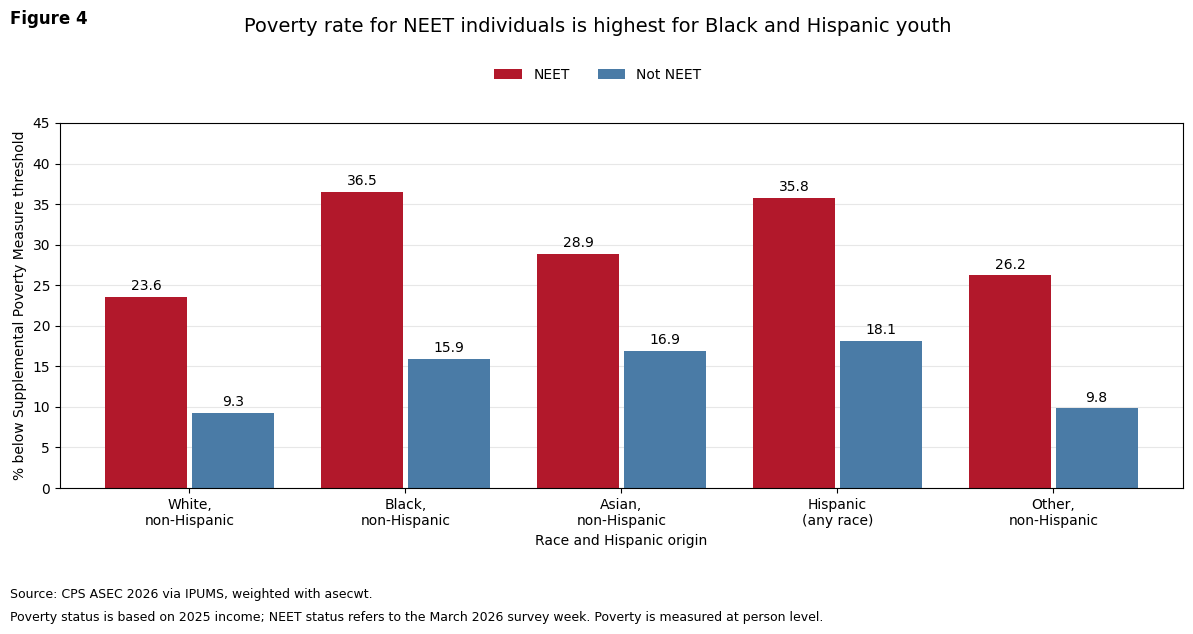

In [18]:
chart_title = "Poverty rate for NEET individuals is highest for Black and Hispanic youth"  # chart title: replace this text with your own sentence

print("Table 5. Poverty rate (SPM), % poor, by race and Hispanic origin and NEET status, 2026 (weighted with asecwt). * = fewer than 30 unweighted respondents. Figure 4 shows this table.")  # table title
print(shown.to_string())  # table, 1 decimal, asterisks

group_names = list(race_rows)  # the five race groups, in the same order as the table rows
bar_names = list(table.columns[:2])  # NEET first, then Not NEET
colors = ["#b2182b", "#4a7ba6"]  # one color for NEET, another for Not NEET
ymax = int(table[bar_names].max().max() * 1.15 / 5) * 5 + 5  # round number above the highest bar, with room for the labels
asterisk_shown = False  # becomes True if any bar label gets an asterisk

fig, ax = plt.subplots(figsize=(12, 6.5))  # one chart
for g, group_name in enumerate(group_names):  # loop over the five clusters
    for i, bar_name in enumerate(bar_names):  # NEET first, then Not NEET, next to each other
        x = g + (-0.2 if i == 0 else 0.2)  # position of this bar
        value = table.loc[group_name, bar_name]  # poverty rate for this bar
        star = "*" if people.loc[group_name, bar_name] < 30 else ""  # asterisk if fewer than 30 respondents
        asterisk_shown = asterisk_shown or star == "*"  # remember that an asterisk is on the chart
        ax.bar(x, value, width=0.38, color=colors[i], label=bar_name if g == 0 else None)  # the bar
        ax.text(x, value + ymax * 0.01, f"{value:.1f}{star}", ha="center", va="bottom", fontsize=10)  # value above the bar

ax.set_xticks(range(len(group_names)))  # one tick under each cluster
ax.set_xticklabels([textwrap.fill(name, width=12, break_on_hyphens=False) for name in group_names])  # group names on two lines
ax.set_xlim(-0.6, len(group_names) - 0.4)  # room on both sides
ax.set_xlabel("Race and Hispanic origin")  # x-axis label
ax.set_ylabel("% below Supplemental Poverty Measure threshold")  # y-axis label
ax.set_ylim(0, ymax)  # y-axis starts at 0
ax.set_yticks(range(0, ymax + 1, 5))  # y ticks every 5, starting at 0
ax.grid(True, axis="y", alpha=0.3)  # light grid behind the bars
ax.set_axisbelow(True)  # grid lines behind the bars

handles, labels = ax.get_legend_handles_labels()  # NEET and Not NEET
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=2, frameon=False)  # one legend
fig.suptitle(chart_title, fontsize=14, y=0.98)  # chart title
fig.text(0.01, 0.99, "Figure 4", fontsize=12, fontweight="bold", va="top")  # figure label, top left
fig.tight_layout(rect=[0, 0.14, 1, 0.9])  # leave room for the title, legend and notes
fig.text(0.01, 0.085, "Source: CPS ASEC 2026 via IPUMS, weighted with asecwt.", fontsize=9)  # source note
fig.text(0.01, 0.05, "Poverty status is based on 2025 income; NEET status refers to the March 2026 survey week. Poverty is measured at person level.", fontsize=9)  # required note
if asterisk_shown:  # only if an asterisk appears on the chart
    fig.text(0.01, 0.015, "* Based on fewer than 30 respondents.", fontsize=9)  # required note
fig.savefig(fig4_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart

## Write-up (50-100 words)

Question:

Finding: